In [1]:
import numpy as np
import torch
import torch.nn as nn
import os
from tqdm import tqdm
from torch.utils.data import TensorDataset, DataLoader

In [35]:
batch_size = 32
x_dim = 1
input_len = 10000
n_z = 1
n_epoch = 75
num_samples=10000

In [3]:
# output_dir = "dataset_splits"
# data = np.load("dataset_splits/dataset_train.npz")
# valorPsi = data["psi"]
# valorM = data["M"]
# print("valorPsi:", valorPsi)
# print("valorM:", valorM)

In [4]:
open_dir = "dataset_splits"

def carregar_dados(nome):
    data = np.load(os.path.join(open_dir, nome))
    psi = data["psi"]
    M = data["M"]
    return psi, M

psi_train, M_train = carregar_dados("dataset_train.npz")
psi_val, M_val = carregar_dados("dataset_val.npz")
psi_test, M_test = carregar_dados("dataset_test.npz")

In [5]:
psi_mean, psi_std = np.mean(psi_train), np.std(psi_train)
M_mean, M_std = np.mean(M_train), np.std(M_train)
# Aqui, normalizo por média e desvio padrão gaussiana
def normalization(psi, M):
    return (psi - psi_mean) / psi_std, (M - M_mean) / M_std

psi_train, M_train = normalization(psi_train, M_train)
psi_val, M_val = normalization(psi_val, M_val)
psi_test, M_test = normalization(psi_test, M_test)
# print(f"psi_train.shape: {psi_train.shape}  | psi_train.dtype: {psi_train.dtype}")
# print(f"M_train.shape: {M_train.shape}  | M_train.dtype: {M_train.dtype}")

# ()tupla (imutável) --> []tensor ou lista

def toTensor(psi, M):
    y = torch.tensor(psi, dtype=torch.float64).unsqueeze(1)
    x = torch.tensor(M, dtype=torch.float64).unsqueeze(1)

    # print("----- DEBUG: para_tensor -----")
    # print(f"y.shape: {y.shape}  | y.dtype: {y.dtype}")
    # print(f"x.shape: {x.shape}  | x.dtype: {x.dtype}")
    # print(f"y[0] (primeiro exemplo, canal 0, 10 primeiros pontos): {y[0, 0, :10]}")
    # print(f"x[0] (valor de M do primeiro exemplo): {x[0]}")
    # print(f"y[-1] (último exemplo, 10 primeiros pontos): {y[-1, 0, :10]}")
    # print(f"x[-1] (valor de M do último exemplo): {x[-1]}")
    # print("-------------------------------")
    return y, x

y_train, x_train = toTensor(psi_train, M_train)
y_val, x_val = toTensor(psi_val, M_val)
y_test, x_test = toTensor(psi_test, M_test)


In [6]:
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=batch_size, shuffle=False)

In [7]:
class ExtratoFeature(nn.Module):
    # bloco conv compartilhado
    def __init__(self, input_len):
        super().__init__()
        self.conv = nn.Sequential(
            # [DEBUG init] dummy.shape: torch.Size([1, 1, 10000])
            # [DEBUG init] saída das convoluções (dummy): torch.Size([1, 64, 157])
            # [DEBUG init] flat_dim calculado: 10048
            # L_out = (L_in + 2 * padding - kernel_size)/stride + 1
            nn.Conv1d(1, 16, kernel_size = 7, stride = 4, padding = 3), # (10000 + 2*3 - 7)/4 + 1 = 2500.75 = 2500
            nn.LeakyReLU(0.2),
            nn.Conv1d(16, 32, kernel_size = 7, stride = 4, padding = 3), # (2500 + 2*3 - 7)/4 + 1 = 625
            nn.LeakyReLU(0.2),
            nn.Conv1d(32, 64, kernel_size = 7, stride = 4, padding = 3), # (625 + 2*3 - 7)/4 + 1 = 157 
            nn.LeakyReLU(0.2),
        )
        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_len)
            # print(f"[DEBUG init] dummy.shape: {dummy.shape}")
            out = self.conv(dummy)
            # print(f"[DEBUG init] saída das convoluções (dummy): {out.shape}")
            self.flat_dim = out.view(1, -1).shape[1]
            # print(f"[DEBUG init] flat_dim calculado: {self.flat_dim}")

    def forward(self, y):
        # y = [batch, 1, input_len]
        # [DEBUG forward] y (entrada): torch.Size([32, 1, 10000])
        # [DEBUG forward] h (após conv, antes de achatar): torch.Size([32, 64, 157])
        # [DEBUG forward] h.view(h.size(0), -1): torch.Size([32, 10048])
        # Espera-se cada batch, achate os 64 canais / vetores com dimensão 157 --> 64 * 157 = 10048
        # print(f"[DEBUG forward] y (entrada): {y.shape}")
        h = self.conv(y)
        # print(f"[DEBUG forward] h (após conv, antes de achatar): {h.shape}")
        # print(f"[DEBUG forward] h.view(h.size(0), -1): {(h.view(h.size(0), -1)).shape}")
        return h.view(h.size(0), -1)

In [8]:
class PriorNet(nn.Module):  # rtheta 1
    def __init__(self, flat_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            # Não é mais conv1d, pois não estamos trabalhando com série temporal, apenas vetores com valores processados
            nn.Linear(flat_dim, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, n_z)
        self.fc_logvar = nn.Linear(128, n_z)

    def forward(self, y_features):
        # [DEBUG PriorNet] mean_p: torch.Size([32, 4])
        # [DEBUG PriorNet] logvar_p: torch.Size([32, 4])
        h = self.fc(y_features)
        mean_p = self.fc_mean(h)
        logvar_p = self.fc_logvar(h)
        # print(f"[DEBUG PriorNet] mean_p: {mean_p.shape}")
        # print(f"[DEBUG PriorNet] logvar_p: {logvar_p.shape}")
        return mean_p, logvar_p

In [9]:
class Encoder(nn.Module): # q phi
    def __init__(self, flat_dim, x_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(flat_dim + x_dim, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, n_z)
        self.fc_logvar = nn.Linear(128, n_z)

    def forward(self, y_features, x):
        # print(f"[DEBUG Encoder] y_features: {y_features.shape}")
        # print(f"[DEBUG Encoder] x: {x.shape}")
        h_in = torch.cat([y_features, x], dim=1)
        # print(f"[DEBUG Encoder] h_in (após concatenar): {h_in.shape}")
        h = self.fc(h_in)
        mean_q = self.fc_mean(h)
        logvar_q = self.fc_logvar(h)
        # print(f"[DEBUG Encoder] mean_q: {mean_q.shape}")
        # print(f"[DEBUG Encoder] logvar_q: {logvar_q.shape}")
        return mean_q, logvar_q

In [10]:
class Decoder(nn.Module): # r thetha 2
    def __init__(self, flat_dim, x_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(flat_dim + n_z, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, x_dim)
        # self.fc_logvar = nn.Linear(128, x_dim) removo logvar por considerar modelo MSE

    def forward(self, y_features, x):
        h_in = torch.cat([y_features, x], dim=1)
        h = self.fc(h_in)
        mean_x = self.fc_mean(h)
        # print(f"[DEBUG Decoder] mean_x: {mean_x.shape}")
        return mean_x

In [ ]:
class CVAE(nn.Module):
    def __init__(self, input_len, x_dim, n_z):
        super().__init__()
        self.feature_extractor = ExtratoFeature(input_len)
        flat_dim = self.feature_extractor.flat_dim

        self.prior_net = PriorNet(flat_dim, n_z)
        self.encoder = Encoder(flat_dim, x_dim, n_z)
        self.decoder = Decoder(flat_dim, x_dim, n_z)

    def reparameterize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mean + eps * std

    def forward(self, x, y):
        # y = [batch, 1, input_len], x = [batch, x_dim]
        y_features = self.feature_extractor(y)
        mean_p, logvar_p = self.prior_net(y_features)
        mean_q, logvar_q = self.encoder(y_features, x)
        z = self.reparameterize(mean_q, logvar_q)
        mean_x = self.decoder(y_features, z) # remoção de logvar_x por considerar modelo MSE
        return mean_x, mean_q, logvar_q, mean_p, logvar_p

    def sample(self, y, num_samples):
        #inferência realiza amostragem do prior p(z|y) e gera amostras de x
        self.eval()
        with torch.no_grad():
            y_features = self.feature_extractor(y)
            mean_p, logvar_p = self.prior_net(y_features)
            
            mean_p = mean_p.repeat(num_samples, 1)
            logvar_p = logvar_p.repeat(num_samples, 1)
            y_features_rep = y_features.repeat(num_samples, 1)

            z = self.reparameterize(mean_p, logvar_p)

            mean_x = self.decoder(y_features_rep, z)
        return mean_x

In [12]:
def loss_cvae_gw(x, mean_x, mean_q, logvar_q, mean_p, logvar_p):
    # Reconstrução: -log N(x; mean_x, exp(logvar_x)), variância APRENDIDA, não fixa
    # var_x = logvar_x.exp()
    # recon_loss = torch.sum(
    #     (x - mean_x).pow(2) / (2 * var_x) + 0.5 * logvar_x,
    #     dim=1  # soma sobre as dimensões de x (o "i" da reconstrução, se x_dim > 1)
    # )
    recon_loss = torch.sum(
        (x - mean_x).pow(2) / (2),
        dim=1  # Considerando que a variância é 1, então o termo de logvar_x desaparece e o denominador é 2
    )

    # KL entre q_phi(z|x,y) e r_theta1(z|y)
    var_q = logvar_q.exp()
    var_p = logvar_p.exp()
    kl = torch.sum(
        0.5 * (logvar_p - logvar_q) + (var_q + (mean_q - mean_p).pow(2)) / (2 * var_p) - 0.5,
        dim=1  # soma sobre as dimensões de z (o "i" do KL)
    )

    H = torch.mean(recon_loss + kl)  # média sobre o batch (o "1/N * sum_n")
    return H

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CVAE(input_len, x_dim, n_z).double().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
from torchinfo import summary

input_shapes = [(batch_size, x_dim), (batch_size, 1, input_len)]

summary(model, input_size=input_shapes, dtypes=[torch.float64, torch.float64])

Layer (type:depth-idx)                   Output Shape              Param #
CVAE                                     [32, 1]                   --
├─ExtratoFeature: 1-1                    [32, 10048]               --
│    └─Sequential: 2-1                   [32, 64, 157]             --
│    │    └─Conv1d: 3-1                  [32, 16, 2500]            128
│    │    └─LeakyReLU: 3-2               [32, 16, 2500]            --
│    │    └─Conv1d: 3-3                  [32, 32, 625]             3,616
│    │    └─LeakyReLU: 3-4               [32, 32, 625]             --
│    │    └─Conv1d: 3-5                  [32, 64, 157]             14,400
│    │    └─LeakyReLU: 3-6               [32, 64, 157]             --
├─PriorNet: 1-2                          [32, 1]                   --
│    └─Sequential: 2-2                   [32, 128]                 --
│    │    └─Linear: 3-7                  [32, 1024]                10,290,176
│    │    └─LeakyReLU: 3-8               [32, 1024]                --

In [14]:
def mae_metric(x, mean_x):
    return torch.mean(torch.abs(x - mean_x)).item()

In [47]:
history = {"train_loss": [], "val_loss": [], "train_mae": [], "val_mae": []}

best_val_loss = float('inf')
checkpoint_path = "melhor_modelo_cvae.pth"


for epoch in tqdm(range(n_epoch), desc="Épocas"):
    # --- treino ---
    model.train()
    train_loss, train_mae = 0.0, 0.0
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.double().to(device)
        y_batch = y_batch.double().to(device)

        optimizer.zero_grad()
        mean_x, mean_q, logvar_q, mean_p, logvar_p = model(x_batch, y_batch)
        loss = loss_cvae_gw(x_batch, mean_x, mean_q, logvar_q, mean_p, logvar_p)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_mae += mae_metric(x_batch, mean_x)

    # --- validação ---
    model.eval()
    val_loss, val_mae = 0.0, 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.double().to(device)
            y_batch = y_batch.double().to(device)
            mean_x, mean_q, logvar_q, mean_p, logvar_p = model(x_batch, y_batch)

            # print(f"[DEBUG] x_batch: {x_batch.shape} | dtype: {x_batch.dtype}")
            # print(f"[DEBUG] y_batch: {y_batch.shape} | dtype: {y_batch.dtype}")
            # print(f"[DEBUG] mean_x: {mean_x.shape}")
            # print(f"[DEBUG] logvar_x: {logvar_x.shape}")
            # print(f"[DEBUG] mean_q: {mean_q.shape}")
            # print(f"[DEBUG] logvar_q: {logvar_q.shape}")
            # print(f"[DEBUG] mean_p: {mean_p.shape}")
            # print(f"[DEBUG] logvar_p: {logvar_p.shape}")
            
            loss = loss_cvae_gw(x_batch, mean_x, mean_q, logvar_q, mean_p, logvar_p)

            val_loss += loss.item()
            val_mae += mae_metric(x_batch, mean_x)


    current_val_loss = val_loss / len(val_loader)
    # médias por época
    history["train_loss"].append(train_loss / len(train_loader))
    history["val_loss"].append(val_loss / len(val_loader))
    history["train_mae"].append(train_mae / len(train_loader))
    history["val_mae"].append(val_mae / len(val_loader))
    # Calcula a média por batch

    print(f"Epoch {epoch+1}/{n_epoch} | Train Loss: {history['train_loss'][-1]:.8f} | "
          f"Val Loss: {history['val_loss'][-1]:.8f} | Train MAE: {history['train_mae'][-1]:.8f} | "
          f"Val MAE: {history['val_mae'][-1]:.8f}")

    if current_val_loss < best_val_loss:
        best_val_loss = current_val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print(f"   -> [Salvo] Novo melhor modelo salvo com Val Loss: {best_val_loss:.8f}")

Épocas:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch 1/75 | Train Loss: 0.02631648 | Val Loss: 0.00008601 | Train MAE: 0.08150911 | Val MAE: 0.00859259


Épocas:   1%|▏         | 1/75 [03:39<4:30:56, 219.68s/it]

   -> [Salvo] Novo melhor modelo salvo com Val Loss: 0.00008601
Epoch 2/75 | Train Loss: 0.00004708 | Val Loss: 0.00003718 | Train MAE: 0.00652221 | Val MAE: 0.00552096


Épocas:   3%|▎         | 2/75 [06:34<3:54:51, 193.03s/it]

...

Epoch 73/75 | Train Loss: 0.00001197 | Val Loss: 0.00005710 | Train MAE: 0.00331536 | Val MAE: 0.00972497


Épocas:  99%|█████████▊| 74/75 [3:33:50<03:04, 184.23s/it]

Epoch 74/75 | Train Loss: 0.00000827 | Val Loss: 0.00001471 | Train MAE: 0.00289510 | Val MAE: 0.00437228


Épocas: 100%|██████████| 75/75 [3:36:54<00:00, 173.52s/it]

Epoch 75/75 | Train Loss: 0.00004356 | Val Loss: 0.00001567 | Train MAE: 0.00625218 | Val MAE: 0.00460468


In [24]:
import matplotlib.pyplot as plt
checkpoint_path = "nona teste/melhor_modelo_cvae.pth"
import os, time
print(os.path.abspath(checkpoint_path), time.ctime(os.path.getmtime(checkpoint_path)))
print("x_test[0]:", x_test[0].item(), "| y_test[0,0,:3]:", y_test[0, 0, :3])

d:\Deeplearning\Pratico\extra\Mathematica\nona teste\melhor_modelo_cvae.pth Fri Oct  9 21:17:10 2026
x_test[0]: -0.29921958630996837 | y_test[0,0,:3]: tensor([0.3245, 0.5397, 0.7541], dtype=torch.float64)


[DEBUG] y_observado.shape: torch.Size([1, 1, 10000]) | dtype: torch.float64
[DEBUG] mean_x.shape: (10000, 1) | dtype: float64
Valor verdadeiro de M: -0.299220
Valor predito médio de M: -0.299613
Erro: -0.000393
MAE das amostras: 0.000402
Desvio padrão das amostras: 0.0002


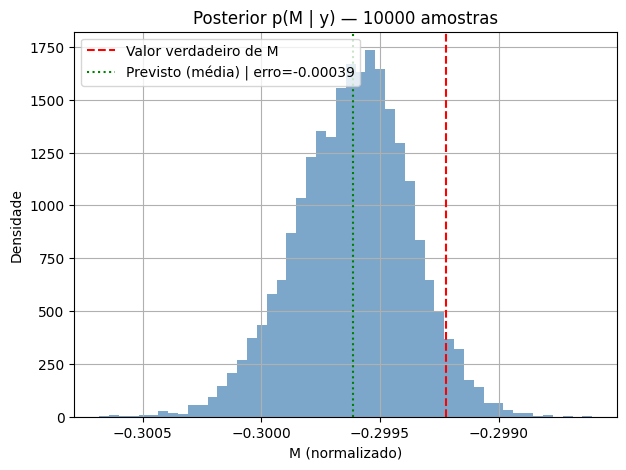

In [41]:

model.load_state_dict(torch.load(checkpoint_path))
model.eval()
y_observado = y_test[0:1]  # um único exemplo do conjunto de teste, shape [1, 1, input_len]
print(f"[DEBUG] y_observado.shape: {y_observado.shape} | dtype: {y_observado.dtype}")

# x_samples = model.sample(y_observado, num_samples=1000)  # shape [1000, x_dim]
# x_samples = x_samples.cpu().numpy()

mean_x = model.sample(y_observado, num_samples)
mean_x = mean_x.cpu().numpy()
print(f"[DEBUG] mean_x.shape: {mean_x.shape} | dtype: {mean_x.dtype}")

x_true = x_test[0].item()  # valor verdadeiro de M para o exemplo de teste
amostras = mean_x[:, 0]  # extrai a primeira dimensão (M) das amostras
predito_medio = np.mean(amostras)
erro = predito_medio - x_true
print(f"Valor verdadeiro de M: {x_true:.6f}")
print(f"Valor predito médio de M: {predito_medio:.6f}")
print(f"Erro: {erro:.6f}")
mae_amostras = np.mean(np.abs(amostras - x_true))
desvio = amostras.std()
print(f"MAE das amostras: {mae_amostras:.6f}")
print(f"Desvio padrão das amostras: {desvio:.4f}")



plt.figure(figsize=(7,5))
plt.hist(mean_x[:, 0], bins=50, density=True, alpha=0.7, color='steelblue')
plt.axvline(x_test[0].item(), color='red', linestyle='--', label='Valor verdadeiro de M')
plt.axvline(predito_medio, color="green", linestyle=":", label=f"Previsto (média) | erro={erro:+.5f}")
plt.legend()
plt.xlabel("M (normalizado)")
plt.ylabel("Densidade")
plt.title(f"Posterior p(M | y) — {num_samples} amostras")
plt.legend()
plt.grid(True)
plt.show()

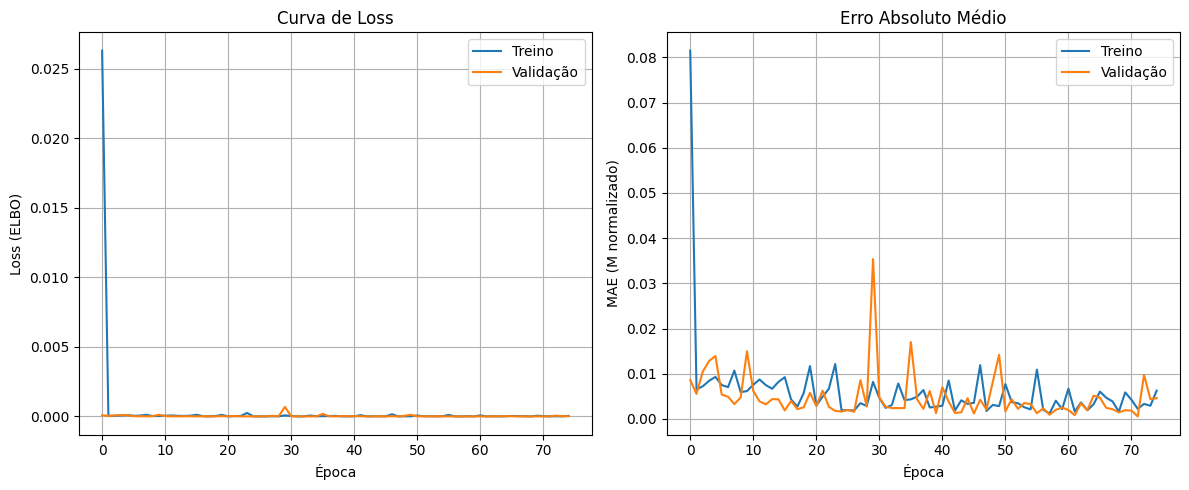

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history["train_loss"], label="Treino")
axes[0].plot(history["val_loss"], label="Validação")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss (ELBO)")
axes[0].set_title("Curva de Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["train_mae"], label="Treino")
axes[1].plot(history["val_mae"], label="Validação")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MAE (M normalizado)")
axes[1].set_title("Erro Absoluto Médio")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [42]:

def sample_posterior(model, y_single, num_samples, device="cpu"):
    model.eval()
    with torch.no_grad():
        y_single = y_single.double().to(device)
        y_features = model.feature_extractor(y_single)
        mean_p, logvar_p = model.prior_net(y_features)
        mean_p = mean_p.repeat(num_samples, 1)
        logvar_p = logvar_p.repeat(num_samples, 1)
        y_features_rep = y_features.repeat(num_samples, 1)
        z = model.reparameterize(mean_p, logvar_p)
        mean_x = model.decoder(y_features_rep, z) 
    return mean_x.cpu().numpy()

percentis = []
for i in tqdm(range(len(x_test)), desc="Avaliando calibração"):
    y_i = y_test[i:i+1]
    x_true = x_test[i].item()
    x_samples = sample_posterior(model, y_i, num_samples, device=device)
    p = np.mean(x_samples[:, 0] < x_true)
    percentis.append(p)

percentis = np.array(percentis)

percentis_ordenados = np.sort(percentis)
N = len(percentis_ordenados)
percentil_nominal = np.arange(1, N+1) / N

plt.figure(figsize=(6,6))
plt.plot(percentil_nominal, percentis_ordenados, marker='.', linestyle='none', label="Modelo")
plt.plot([0,1], [0,1], 'k--', label="Calibração perfeita")
plt.xlabel("Percentil nominal (esperado)")
plt.ylabel("Fração observada de casos abaixo")
plt.title("P-P Plot — Calibração da Posterior")
plt.legend()
plt.grid(True)
plt.show()

Avaliando calibração:   0%|          | 0/2000 [00:05<?, ?it/s]


KeyboardInterrupt: 

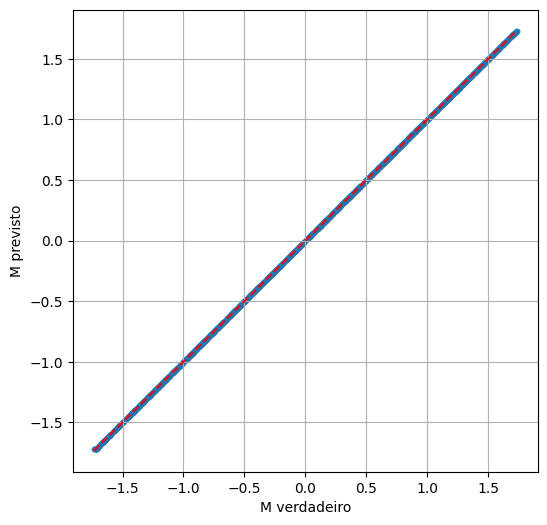

In [51]:
model.eval()
preds, trues = [], []
with torch.no_grad():
    for i in range(len(x_test)):
        y_i = y_test[i:i+1].double().to(device)
        y_features = model.feature_extractor(y_i)
        mean_p, logvar_p = model.prior_net(y_features)
        z = mean_p  # sem ruído, só a média
        mean_x= model.decoder(y_features, z)
        preds.append(mean_x.item())
        trues.append(x_test[i].item())

plt.figure(figsize=(6,6))
plt.scatter(trues, preds, alpha=0.4, s=10)
plt.plot([min(trues), max(trues)], [min(trues), max(trues)], 'r--')
plt.xlabel("M verdadeiro"); plt.ylabel("M previsto"); plt.grid(True)
plt.show()

In [54]:
model.eval()
with torch.no_grad():
    y_i = y_test[0:1].double().to(device)
    y_features = model.feature_extractor(y_i)
    mean_p, logvar_p = model.prior_net(y_features)
    std_p = logvar_p.exp().sqrt()
    print(f"mean_p: {mean_p} | std_p: {std_p}")
    print(f"mean_p.shape: {mean_p.shape} | dtype: {mean_p.dtype}")

    print(f"mean_p: {mean_p.item():.4f} | std_p: {std_p.item():.4f}")
    print(f"x verdadeiro: {x_test[0].item():.4f}\n")

    for k in [-3, -2, -1, -0.5, 0, 0.5, 1, 2, 3]:
        z_k = mean_p + k * std_p
        mean_x_k = model.decoder(y_features, z_k)
        print(f"  z = mean_p {k:+.1f}·std_p  ->  mean_x = {mean_x_k.item():.4f}")

mean_p: tensor([[-0.0393]], dtype=torch.float64) | std_p: tensor([[0.9846]], dtype=torch.float64)
mean_p.shape: torch.Size([1, 1]) | dtype: torch.float64
mean_p: -0.0393 | std_p: 0.9846
x verdadeiro: -0.2992

  z = mean_p -3.0·std_p  ->  mean_x = -0.3005
  z = mean_p -2.0·std_p  ->  mean_x = -0.3001
  z = mean_p -1.0·std_p  ->  mean_x = -0.2999
  z = mean_p -0.5·std_p  ->  mean_x = -0.2997
  z = mean_p +0.0·std_p  ->  mean_x = -0.2996
  z = mean_p +0.5·std_p  ->  mean_x = -0.2995
  z = mean_p +1.0·std_p  ->  mean_x = -0.2994
  z = mean_p +2.0·std_p  ->  mean_x = -0.2991
  z = mean_p +3.0·std_p  ->  mean_x = -0.2989


In [55]:

print("Checando se as variáveis existem...")
print("model existe?", 'model' in dir())
print("y_test existe?", 'y_test' in dir())
print("device existe?", 'device' in dir())

model.eval()
with torch.no_grad():
    y_i = y_test[0:1].double().to(device)
    print("y_i.shape:", y_i.shape)

    y_features = model.feature_extractor(y_i)
    print("y_features.shape:", y_features.shape)

    mean_p, logvar_p = model.prior_net(y_features)
    print("mean_p.shape:", mean_p.shape)
    print("logvar_p.shape:", logvar_p.shape)

    print("mean_p valor:", mean_p)
    print("logvar_p valor:", logvar_p)

    var_p = logvar_p.exp()
    print("var_p valor:", var_p)

    model.eval()
with torch.no_grad():
    y_i = y_test[0:1].double().to(device)
    y_features = model.feature_extractor(y_i)
    mean_p, logvar_p = model.prior_net(y_features)
    print("logvar_p:", logvar_p.item())
    print("var_p (exp):", logvar_p.exp().item())


Checando se as variáveis existem...
model existe? True
y_test existe? True
device existe? True
y_i.shape: torch.Size([1, 1, 10000])
y_features.shape: torch.Size([1, 10048])
mean_p.shape: torch.Size([1, 1])
logvar_p.shape: torch.Size([1, 1])
mean_p valor: tensor([[-0.0393]], dtype=torch.float64)
logvar_p valor: tensor([[-0.0309]], dtype=torch.float64)
var_p valor: tensor([[0.9695]], dtype=torch.float64)
logvar_p: -0.030940244377749393
var_p (exp): 0.9695335064230562


In [56]:

model.eval()
with torch.no_grad():
    y_i = y_test[0:1].double().to(device)
    x_i = x_test[0:1].double().to(device)

    y_features = model.feature_extractor(y_i)
    mean_q, logvar_q = model.encoder(y_features, x_i)
    mean_p, logvar_p = model.prior_net(y_features)

    print("mean_q:", mean_q.cpu().numpy())
    print("mean_p:", mean_p.cpu().numpy())
    print("logvar_q:", logvar_q.cpu().numpy())
    print("logvar_p:", logvar_p.cpu().numpy())

mean_q: [[-0.0393076]]
mean_p: [[-0.03932461]]
logvar_q: [[-0.03099534]]
logvar_p: [[-0.03094024]]


In [58]:
model.eval()
with torch.no_grad():
    y_i = y_test[0:1].double().to(device)
    y_features = model.feature_extractor(y_i)
    mean_p, logvar_p = model.prior_net(y_features)
    std_p = logvar_p.exp().sqrt()

    z_menos = mean_p - 3*std_p
    z_mais = mean_p + 3*std_p

    mean_x_menos = model.decoder(y_features, z_menos)
    mean_x_mais = model.decoder(y_features, z_mais)

    delta_z = (z_mais - z_menos).item()
    delta_mean_x = (mean_x_mais - mean_x_menos).item()

    sensibilidade = delta_mean_x / delta_z  # quanto mean_x muda por unidade de z

    print(f"Δz: {delta_z:.4f}")
    print(f"Δmean_x: {delta_mean_x:.6f}")
    print(f"Sensibilidade (∂mean_x/∂z, aproximada): {sensibilidade:.6f}")

Δz: 5.9079
Δmean_x: 0.001550
Sensibilidade (∂mean_x/∂z, aproximada): 0.000262


In [59]:

model.eval()
errs, spreads, kls, mq, xs = [], [], [], [], []
with torch.no_grad():
    for i in range(len(x_test)):
        y_i = y_test[i:i+1].double().to(device)
        x_i = x_test[i:i+1].double().to(device)
        yf = model.feature_extractor(y_i)
        mp, lp = model.prior_net(yf)
        mq_i, lq = model.encoder(yf, x_i)

        mx = model.decoder(yf, mp)                       # sem ruído
        errs.append((mx - x_i).item())

        z = model.reparameterize(mp.repeat(200,1), lp.repeat(200,1))
        mxs = model.decoder(yf.repeat(200,1), z)
        spreads.append(mxs.std().item())                    # largura da nuvem por z

        kl = 0.5*(lp-lq) + (lq.exp()+(mq_i-mp)**2)/(2*lp.exp()) - 0.5
        kls.append(kl.sum().item())
        mq.append(mq_i.item()); xs.append(x_i.item())

errs, spreads = np.array(errs), np.array(spreads)
print(f"viés médio (mean_x - x): {errs.mean():+.5f}")
print(f"desvio do erro:          {errs.std():.5f}")
print(f"largura média da nuvem:  {spreads.mean():.5f}")
print(f"KL médio:                {np.mean(kls):.2e}")
print(f"corr(mean_q, x):         {np.corrcoef(mq, xs)[0,1]:.3f}")

viés médio (mean_x - x): -0.00026
desvio do erro:          0.00085
largura média da nuvem:  0.00009
KL médio:                2.77e-09
corr(mean_q, x):         -0.985


In [ ]:
def posterior_samples(model, y_single, num_samples, sigma_x=0.0):
    model.eval()
    with torch.no_grad():
        y_single = y_single.double().to(device)
        yf = model.feature_extractor(y_single)
        mp, lp = model.prior_net(yf)
        z = model.reparameterize(mp.repeat(num_samples, 1), lp.repeat(num_samples, 1))
        mx = model.decoder(yf.repeat(num_samples, 1), z)
        if sigma_x > 0:
            mx = mx + sigma_x * torch.randn_like(mx)   # ruído gaussiano da saída
    return mx.cpu().numpy()[:, 0]

def calcular_percentis(model, y_set, x_set, sigma_x=0.0, num_samples = num_samples):
    ps = []
    for i in tqdm(range(len(x_set)), desc=f"percentis (sigma_x={sigma_x})"):
        s = posterior_samples(model, y_set[i:i+1], num_samples, sigma_x)
        ps.append(np.mean(s < x_set[i].item()))
    return np.array(ps)

def pp_plot(percentis, titulo):
    alphas = np.linspace(0, 1, 201)
    frac = [np.mean(percentis <= a) for a in alphas]   # CDF empírica dos percentis
    plt.figure(figsize=(6, 6))
    plt.plot(alphas, frac, label="Modelo")
    plt.plot([0, 1], [0, 1], "k--", label="Calibração perfeita")
    plt.xlabel("Nível nominal α")
    plt.ylabel("Fração de exemplos com percentil ≤ α")
    plt.title(titulo); plt.legend(); plt.grid(True); plt.show()

# 0) garantir o checkpoint certo
model.load_state_dict(torch.load(checkpoint_path))
model.eval()

# 1) sigma calibrado: erro RMS de mean_x no conjunto de VALIDAÇÃO (não no teste)
with torch.no_grad():
    res = []
    for i in range(len(x_val)):
        yf = model.feature_extractor(y_val[i:i+1].double().to(device))
        mp, _ = model.prior_net(yf)
        mx = model.decoder(yf, mp)
        res.append(mx.item() - x_val[i].item())
sigma_cal = float(np.sqrt(np.mean(np.square(res))))
print("sigma calibrado (validação):", sigma_cal)

# 2) três versões de posterior no teste
p_sem_ruido = calcular_percentis(model, y_test, x_test, sigma_x=0.0)
p_sigma_1   = calcular_percentis(model, y_test, x_test, sigma_x=1.0)
p_cal       = calcular_percentis(model, y_test, x_test, sigma_x=sigma_cal)

pp_plot(p_sem_ruido, "Só variação de z (sem ruído na saída)")
pp_plot(p_sigma_1,   "Ruído N(0,1) na saída (o que a loss assume)")
pp_plot(p_cal,       "Ruído com sigma calibrado na validação")

# 3) checagem de consistência: percentil < 0.5 deve coincidir com mean_x > x
errs_test = []
with torch.no_grad():
    for i in range(len(x_test)):
        yf = model.feature_extractor(y_test[i:i+1].double().to(device))
        mp, _ = model.prior_net(yf)
        mx = model.decoder(yf, mp)
        errs_test.append(mx.item() - x_test[i].item())
errs_test = np.array(errs_test)
print("fração com mean_x > x:      ", np.mean(errs_test > 0))
print("fração com percentil < 0.5: ", np.mean(p_sem_ruido < 0.5))

sigma calibrado (validação): 0.0008919781658938822


percentis (sigma_x=1.0):  19%|█▉        | 375/2000 [04:52<21:08,  1.28it/s]  


KeyboardInterrupt: 